# Behavior + video alignment test
Demo of `src/behavior/` on one cohort 3 cagemate session.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[2]  # repo root (notebook lives in src/<pkg>/test)
sys.path.insert(0, str(ROOT))
H5 = ROOT / "exports/cagemate_h5/cohort3_bla_cohort2_CM/11_4_d_CM_11_3_s_20260729_125055.h5"

import glob
from IPython.display import Video
from src.behavior import boris as B, video as V
from src.rsp import resp_processing as rp

LAB = Path(r"C:/Users/thoma/UF Dropbox/Thomas Heeps/Padilla-Coreano Lab")
SESSION = LAB / "2026/BLA_ChR_resp_cohort2/BLA_ChR_resp_CM_hc/11_4_d_CM_11_3_s_20260729_125055.rec"
MP4 = str(SESSION / "11_4_d_CM_11_3_s_20260729_125055.1.mp4")
BORIS_FILES = glob.glob(str(SESSION.parent / "BORIS_csv" / "*20260729_125055*.csv"))
OUT = Path("output"); OUT.mkdir(exist_ok=True)

## `load_video_timing`
Frame times on the respiration clock, from the H5.

In [2]:
timing = V.load_video_timing(H5)
print({k: v for k, v in timing.items() if np.isscalar(v)})
print("first frames (s from resp start):", timing["frame_time_sec"][:3].round(3))

{'n_frames': 9355, 'mp4_fps': 15.0, 'capture_fps': 15.000209660487197, 'n_camera_gaps': 0}
first frames (s from resp start): [0.02  0.087 0.153]


## `read_boris`
Load one export; handles tab-separated files and old/Mac column names.

In [3]:
raw_dfs = [B.read_boris(p) for p in BORIS_FILES]
raw_dfs[0][["Subject", "Behavior", "Start (s)", "Stop (s)", "FPS (frame/s)", "Image index start"]].head()

,Subject,Behavior,Start (s),Stop (s),FPS (frame/s),Image index start
0,social_agent,anogenital sniffing,314.733,315.200,15.0,4722
1,social_agent,anogenital sniffing,316.533,317.399,15.0,4749
2,subject,anogenital sniffing,316.800,317.132,15.0,4753
3,subject,body sniffing,317.133,318.266,15.0,4758
4,social_agent,body sniffing,317.400,317.867,15.0,4762


## `clean_boris`
Lower-case names, keep real actors, drop duplicates and <1-frame bouts.

In [4]:
clean_dfs = [B.clean_boris(d) for d in raw_dfs]
print([len(d) for d in raw_dfs], "->", [len(d) for d in clean_dfs], "bouts")

[189] -> [185] bouts


## `combine_boris`
One table per session from all its exports.

In [5]:
beh = B.combine_boris(clean_dfs)
print(len(beh), "bouts;", beh["Subject"].value_counts().to_dict())

185 bouts; {'social_agent': 114, 'subject': 71}


## `boris_to_frames`
BORIS seconds → mp4 frame (seconds × FPS).

In [6]:
beh = B.boris_to_frames(beh, timing)
print("method:", beh["frame_method"].iloc[0], "| Image index offset (frames):",
      beh["image_index_offset"].describe()[["min", "max"]].round(2).to_dict())
beh[["Behavior", "Start (s)", "start_frame", "Image index start"]].head()

method: exact | Image index offset (frames): {'min': 0.99, 'max': 1.01}


,Behavior,Start (s),start_frame,Image index start
0,anogenital sniffing,314.733,4720.995,4722
1,anogenital sniffing,316.533,4747.995,4749
2,anogenital sniffing,316.800,4752.000,4753
3,body sniffing,317.133,4756.995,4758
4,body sniffing,317.400,4761.000,4762


## `frames_to_resp`
mp4 frame → seconds on the respiration clock.

In [7]:
beh = B.frames_to_resp(beh, timing)
beh[["Subject", "Behavior", "Start (s)", "start_resp_sec", "duration_resp_sec"]].head()

,Subject,Behavior,Start (s),start_resp_sec,duration_resp_sec
0,social_agent,anogenital sniffing,314.733,314.748503,0.466993
1,social_agent,anogenital sniffing,316.533,316.548477,0.865988
2,subject,anogenital sniffing,316.800,316.815474,0.331995
3,subject,body sniffing,317.133,317.148469,1.132984
4,social_agent,body sniffing,317.400,317.415465,0.466993


## `merge_bouts`
Join bouts < 0.5 s apart, drop bouts < 0.5 s.

In [8]:
merged = B.merge_bouts(beh, min_gap_s=0.5, min_bout_s=0.5)
print(len(beh), "->", len(merged), "bouts")

185 -> 80 bouts


## `read_frame`
One exact video frame.

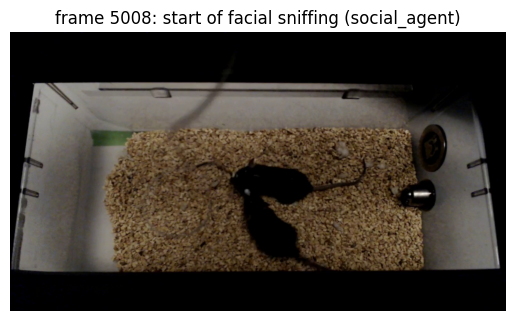

In [9]:
first_sniff = beh[beh["Behavior"] == "facial sniffing"].iloc[0]
k = int(round(first_sniff["start_frame"]))
plt.imshow(V.read_frame(MP4, k)); plt.axis("off")
plt.title(f"frame {k}: start of facial sniffing ({first_sniff['Subject']})"); plt.show()

## `plot_ethogram`
Bouts over time, with respiration below.

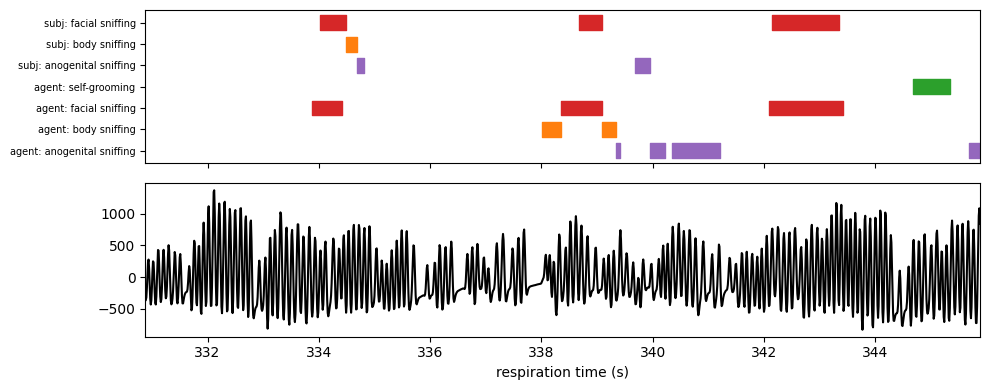

In [10]:
resp, t = rp.preprocess_resp(rp.load_raw_resp(H5))
t0 = first_sniff["start_resp_sec"] - 3
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
V.plot_ethogram(beh, t0, t0 + 15, ax[0])
w = (t >= t0) & (t <= t0 + 15)
ax[1].plot(t[w], resp[w], color="k"); ax[1].set_xlabel("respiration time (s)")
plt.tight_layout(); plt.show()

## `make_alignment_clip`
Video, ethogram and respiration side by side, in real time.

In [11]:
clip = V.make_alignment_clip(MP4, timing, beh, resp, t, t0, 15, str(OUT / "alignment_clip.mp4"))
Video(clip, embed=True, width=500)

## `convert_h264_to_mp4`
Raw Trodes .h264 → mp4 at the capture fps (first 5 s here).

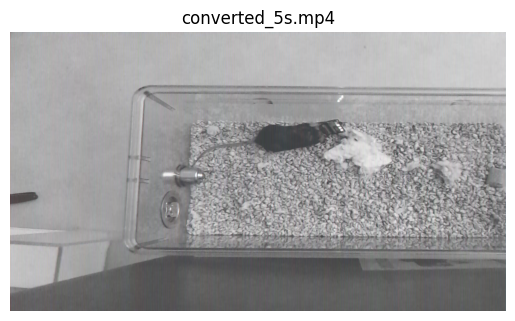

In [12]:
h264 = glob.glob(str(ROOT / "test_data/trodes_recordings/sub_5_13_baseline_*.rec/*.h264"))[0]
mp4 = V.convert_h264_to_mp4(h264, fps=30, out_path=str(OUT / "converted_5s.mp4"), duration_s=5)
plt.imshow(V.read_frame(mp4, 0)); plt.axis("off"); plt.title(Path(mp4).name); plt.show()

## How to use
Typical analysis: BORIS bouts on the respiration clock, then breathing rate per bout.

In [13]:
from src.behavior.boris import read_boris, clean_boris, combine_boris, boris_to_frames, frames_to_resp
from src.behavior.video import load_video_timing

def load_aligned_behavior(h5, boris_files):
    timing = load_video_timing(h5)
    beh = combine_boris([clean_boris(read_boris(p)) for p in boris_files])
    return frames_to_resp(boris_to_frames(beh, timing), timing)

beh = load_aligned_behavior(H5, BORIS_FILES)
beh[["Subject", "Behavior", "start_resp_sec", "stop_resp_sec"]].head()

,Subject,Behavior,start_resp_sec,stop_resp_sec
0,social_agent,anogenital sniffing,314.748503,315.215496
1,social_agent,anogenital sniffing,316.548477,317.414465
2,subject,anogenital sniffing,316.815474,317.147469
3,subject,body sniffing,317.148469,318.281453
4,social_agent,body sniffing,317.415465,317.882459


In [14]:
from src.rsp.resp_processing import load_raw_resp, preprocess_resp, detect_breaths, breathing_rate

resp, t = preprocess_resp(load_raw_resp(H5))
beh["rate_hz"] = [breathing_rate(t, detect_breaths(resp, t, s, e))
                  for s, e in zip(beh["start_resp_sec"], beh["stop_resp_sec"])]
beh[beh["Subject"] == "subject"].groupby("Behavior")["rate_hz"].agg(["count", "mean"]).round(2)

,count,mean
Behavior,,
anogenital sniffing,1,10.96
body sniffing,3,9.57
digging,8,7.85
facial sniffing,3,10.30
self-grooming,5,8.73
